# Notebook A: dữ liệu, làm sạch, SQL và hình RQ1

**Đề tài:** Số giờ cảnh báo trước hỏng máy nén của tàu metro dưới một hạn mức báo động giả và mức tô hồng của chia ngẫu nhiên trên MetroPT-3

**Sinh viên A** chạy lần lượt từ trên xuống. Mỗi ô code có một ô hướng dẫn ngay phía trên gồm ba ý: làm gì, vì sao, kiểm tra gì. Sản phẩm bàn giao cho Notebook B là file parquet trong `data/processed/`, file `sql/queries.sql` và `data/processed/manifest.json`.

## Bước 0. Môi trường

- **Làm gì:** cài thư viện (một lần), tạo thư mục, nạp ba hàm tiện ích.
- **Vì sao:** hai notebook của nhóm dùng chung cấu trúc thư mục để bàn giao file cho nhau.
- **Kiểm tra:** ô chạy xong không báo lỗi.

In [1]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy

In [2]:
import os, glob, zipfile, urllib.request
for d in ['data/raw', 'data/processed', 'report', 'sql']: os.makedirs(d, exist_ok=True)
def fetch(url, name):                                   # download once into data/raw
    path = 'data/raw/' + name
    if not os.path.exists(path): print('downloading', url); urllib.request.urlretrieve(url, path)
    return path
def unzip_all(folder='data/raw'):                       # unpack archives, including archives inside archives
    done = set()
    while True:
        todo = [z for z in glob.glob(folder + '/**/*.zip', recursive=True) if z not in done]
        if not todo: break
        for z in todo:
            with zipfile.ZipFile(z) as f: f.extractall(os.path.dirname(z))
            done.add(z)
def find1(name):                                        # locate one file wherever the archive put it
    hits = glob.glob('data/raw/**/' + name, recursive=True); assert hits, 'not found: ' + name; return hits[0]

## Bước 1a. Tải dữ liệu

- **Làm gì:** tải file gốc về `data/raw/` và giải nén. Ô này bỏ qua nếu dữ liệu đã có.
- **Vì sao:** người khác chạy lại notebook phải nhận đúng cùng một bộ dữ liệu.
- **Kiểm tra:** ô in đường dẫn của từng file cần có. Nếu tải tự động lỗi hoặc thiếu file, tải tay tại `archive.ics.uci.edu/dataset/791`, chép vào `data/raw/` rồi chạy lại ô này.

In [3]:
FILES = [('https://archive.ics.uci.edu/static/public/791/metropt+3+dataset.zip', 'metropt3.zip')]
NEED = ['MetroPT3*.csv']
have = lambda: [glob.glob('data/raw/**/' + n, recursive=True) for n in NEED]
if not all(have()):
    for url, name in FILES:
        try: fetch(url, name)
        except Exception as e: print('download failed:', name, e)
    unzip_all()
for n, hit in zip(NEED, have()):
    assert hit, 'missing ' + n + ': download by hand from archive.ics.uci.edu/dataset/791 into data/raw and run this cell again'
    print(n, '->', hit[0], os.path.getsize(hit[0]) // 1024, 'kB')

downloading https://archive.ics.uci.edu/static/public/791/metropt+3+dataset.zip
MetroPT3*.csv -> data/raw\MetroPT3(AirCompressor).csv 213184 kB


## Bước 1b. Nạp dữ liệu

- **Làm gì:** đọc file gốc, tạo bảng làm việc.
- **Vì sao:** mọi bước sau dùng bảng này, nên số dòng và số cột in ra ở đây là con số ghi vào mục Data của bài.
- **Kiểm tra:** so số dòng, số cột với mô tả của bộ dữ liệu trong đề cương; nếu khác thì ghi lại con số thật.

In [4]:
# Step 1b: MetroPT-3 (Davari et al., 2021; UCI 2023): air production unit of a metro train in Porto, Feb to Aug 2020, 1,516,948 readings, 15 signals
# download (one zip, 208 MB, no account): https://archive.ics.uci.edu/static/public/791/metropt+3+dataset.zip
import pandas as pd, numpy as np, glob, duckdb
src = glob.glob('data/raw/**/MetroPT3*.csv', recursive=True)[0]
ANALOG = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current']
DIGITAL = ['COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']
con = duckdb.connect()                                   # readings every 10 seconds are summarised into one-minute windows inside DuckDB
agg = ', '.join([f'AVG({c}) AS {c}_mean, STDDEV_POP({c}) AS {c}_std, MAX({c}) AS {c}_max' for c in ANALOG] + [f'AVG({c}) AS {c}_share' for c in DIGITAL])
RAW_ROWS = con.execute(f"SELECT COUNT(*) FROM read_csv_auto('{src}')").fetchone()[0]
df = con.execute(f"""SELECT time_bucket(INTERVAL 1 MINUTE, CAST("timestamp" AS TIMESTAMP)) AS ts, COUNT(*) AS n, {agg}
                     FROM read_csv_auto('{src}') GROUP BY 1 ORDER BY 1""").df()
df['ts'] = pd.to_datetime(df.ts); print(RAW_ROWS, 'readings ->', df.shape, df.ts.min(), df.ts.max())

1516948 readings -> (252720, 31) 2020-02-01 00:00:00 2020-09-01 03:59:00


## Bước 2. Làm sạch có nhật ký

- **Làm gì:** kiểm tra miền giá trị, loại dòng lỗi, lưu parquet và nhật ký làm sạch.
- **Vì sao:** phản biện sẽ hỏi vì sao số dòng khác tài liệu gốc; nhật ký là câu trả lời.
- **Kiểm tra:** mở `report/table_cleaning_log.csv`, mỗi dòng bị bỏ phải có lý do.

In [5]:
# Step 2: labels from the company failure reports, frozen-logger windows, cleaning log
FAIL = [('2020-04-18 00:00', '2020-04-18 23:59'), ('2020-05-29 23:30', '2020-05-30 06:00'),      # four air leaks reported by the operator (UCI page)
        ('2020-06-05 10:00', '2020-06-07 14:30'), ('2020-07-15 14:30', '2020-07-15 19:00')]
FAIL = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in FAIL]; HORIZON = pd.Timedelta(hours=2)
log = [['raw readings', RAW_ROWS], ['one-minute windows', len(df)]]
df['failure'] = 0; df['y'] = 0; df['event'] = 0
for i, (a, b) in enumerate(FAIL, 1):
    df.loc[df.ts.between(a, b), 'failure'] = 1
    df.loc[df.ts.between(a - HORIZON, b), ['y', 'event']] = [1, i]       # target: a failure is under way or starts within two hours
df['frozen'] = ((df[[c + '_std' for c in ANALOG]].sum(axis=1) == 0) & (df.n >= 3)).astype(int)     # logger repeats one value
gap = df.ts.diff().dt.total_seconds().fillna(60)
log += [['minutes inside reported failures', int(df.failure.sum())], ['target minutes (failure or two hours before)', int(df.y.sum())],
        ['frozen-logger minutes', int(df.frozen.sum())], ['gaps longer than 10 minutes', int((gap > 600).sum())]]
df['month'] = df.ts.dt.month; df['row_id'] = np.arange(len(df))
pd.DataFrame(log, columns=['step', 'value']).to_csv('report/table_cleaning_log.csv', index=False); print(log)
df.to_parquet('data/processed/metropt.parquet', index=False); print(df.shape)

[['raw readings', 1516948], ['one-minute windows', 252720], ['minutes inside reported failures', 4960], ['target minutes (failure or two hours before)', 5440], ['frozen-logger minutes', 10222], ['gaps longer than 10 minutes', 227]]
(252720, 37)


## Bước 2b. Hiểu dữ liệu trước khi đặt câu hỏi

Mười ô dưới đây đọc lại bảng đã làm sạch và trả lời lần lượt: bảng có những cột gì, phân phối ra sao, thiếu ở đâu, có giá trị lạ không, cột nào liên quan tới mục tiêu và mục tiêu khác nhau thế nào giữa các nhóm. **Quy tắc:** sau mỗi ô, nhóm viết một câu nhận xét có số vào dòng Nhận xét. Hình và mô hình chỉ tốt khi nhóm hiểu dữ liệu ở bước này.

### 2b.1 Nạp bảng sạch và xem năm dòng đầu

- **Làm gì:** đọc file parquet, chọn cột mục tiêu và cột nhóm, lấy mẫu cố định để vẽ nhanh.
- **Kiểm tra:** số dòng khớp với nhật ký làm sạch.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [6]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
E = pd.read_parquet('data/processed/metropt.parquet'); TGT, GRP = 'failure', 'month'
S = E.sample(min(len(E), 50_000), random_state=0)          # a fixed sample keeps every plot fast
NUM = [c for c in S.select_dtypes('number').columns if c != 'row_id' and S[c].nunique() > 1]
print(E.shape[0], 'rows,', E.shape[1], 'columns;', len(NUM), 'numeric columns; target:', TGT, '; group:', GRP); display(E.head(5))

252720 rows, 37 columns; 35 numeric columns; target: failure ; group: month


,ts,n,TP2_mean,TP2_std,TP2_max,TP3_mean,TP3_std,TP3_max,H1_mean,H1_std,...,LPS_share,Pressure_switch_share,Oil_level_share,Caudal_impulses_share,failure,y,event,frozen,month,row_id
0,2020-02-01 00:00:00,7,-0.012286,0.000700,-0.012,9.327429,0.020722,9.358,9.311143,0.020308,...,0.0,1.0,1.0,1.0,0,0,0,0,2,0
1,2020-02-01 00:01:00,6,-0.013000,0.001000,-0.012,9.260000,0.018000,9.286,9.243333,0.017988,...,0.0,1.0,1.0,1.0,0,0,0,0,2,1
2,2020-02-01 00:02:00,6,-0.012667,0.000943,-0.012,9.198333,0.017867,9.224,9.182000,0.017205,...,0.0,1.0,1.0,1.0,0,0,0,0,2,2
3,2020-02-01 00:03:00,6,-0.012333,0.000745,-0.012,9.136667,0.017575,9.162,9.120667,0.017575,...,0.0,1.0,1.0,1.0,0,0,0,0,2,3
4,2020-02-01 00:04:00,6,-0.013000,0.001000,-0.012,9.075667,0.017490,9.100,9.060000,0.017010,...,0.0,1.0,1.0,1.0,0,0,0,0,2,4


### 2b.2 Từ điển dữ liệu

- **Làm gì:** kiểu dữ liệu, tỷ lệ thiếu, số giá trị khác nhau và một ví dụ của từng cột.
- **Vì sao:** bảng này đi thẳng vào mục Data của bài (số dòng, số cột, ý nghĩa cột).
- **Kiểm tra:** cột nào chỉ có một giá trị hoặc thiếu trên 30% thì ghi lại và cân nhắc bỏ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [7]:
dic = pd.DataFrame({'dtype': E.dtypes.astype(str), 'missing_pct': (100 * E.isna().mean()).round(2), 'unique': E.nunique(),
                    'example': E.iloc[0].astype(str).str.slice(0, 40)})
dic.to_csv('report/table_data_dictionary.csv'); display(dic)

,dtype,missing_pct,unique,example
ts,datetime64[us],0.0,252720,2020-02-01 00:00:00
n,int64,0.0,7,7
TP2_mean,float64,0.0,28203,-0.012285714285714526
TP2_std,float64,0.0,47385,0.0006998542122233802
TP2_max,float64,0.0,3392,-0.0120000000000004
TP3_mean,float64,0.0,24948,9.327428571428571
TP3_std,float64,0.0,128131,0.020721673559393323
TP3_max,float64,0.0,2144,9.358
H1_mean,float64,0.0,29940,9.311142857142856
H1_std,float64,0.0,105010,0.02030783502161948


### 2b.3 Thống kê mô tả các cột số

- **Làm gì:** trung bình, độ lệch chuẩn, các phân vị 1%, 50%, 99%, độ lệch (skew) và tỷ lệ giá trị bằng không.
- **Vì sao:** cột lệch mạnh cần biến đổi log hoặc cắt đuôi trước khi vẽ và trước khi đưa vào mô hình tuyến tính.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [8]:
num = S[NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T; num['skew'] = S[NUM].skew()
num['zero_pct'] = (100 * (S[NUM] == 0).mean()).round(1); num.to_csv('report/table_numeric_summary.csv'); display(num.round(3))

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,zero_pct
n,50000.0,6.002,0.354,1.000,5.000,6.000,6.000,6.000,7.000,7.000,-2.793,0.0
TP2_mean,50000.0,1.373,3.063,-0.026,-0.019,-0.014,-0.012,-0.010,9.889,10.432,1.918,0.0
TP2_std,50000.0,0.347,1.042,0.000,0.000,0.001,0.001,0.001,4.883,5.279,3.307,13.2
TP2_max,50000.0,1.777,3.703,-0.022,-0.016,-0.012,-0.010,-0.008,10.528,10.624,1.629,0.0
TP3_mean,50000.0,8.979,0.640,0.808,7.862,8.492,8.953,9.485,10.088,10.203,-1.136,0.0
TP3_std,50000.0,0.051,0.075,0.000,0.000,0.018,0.026,0.039,0.348,1.379,2.947,4.1
TP3_max,50000.0,9.053,0.657,0.888,7.900,8.528,9.028,9.562,10.202,10.302,-0.979,0.0
H1_mean,50000.0,7.557,3.160,-0.026,-0.018,8.231,8.739,9.327,10.025,10.163,-1.750,0.0
H1_std,50000.0,0.310,1.035,0.000,0.000,0.015,0.024,0.034,4.789,5.116,3.484,4.8
H1_max,50000.0,7.930,3.022,-0.022,-0.014,8.318,8.863,9.460,10.190,10.268,-2.134,0.1


### 2b.4 Giá trị thiếu và dòng trùng

- **Làm gì:** vẽ tỷ lệ thiếu của các cột còn thiếu và đếm dòng trùng.
- **Kiểm tra:** mỗi cột còn thiếu phải có cách xử lý ghi trong nhật ký làm sạch.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [9]:
miss = (100 * E.isna().mean()).sort_values(ascending=False); miss = miss[miss > 0].head(12)
print('duplicated rows:', int(S.duplicated().sum()), 'of', len(S), 'sampled rows')
if len(miss): bar_chart(miss.index, miss.values, 'Missing values (%)', 'report/fig_eda_missing.png', highlight=0, fmt='{:.1f}')
else: print('no missing values in the cleaned table')

duplicated rows: 0 of 50000 sampled rows
no missing values in the cleaned table


### 2b.5 Phân phối của mục tiêu

- **Làm gì:** vẽ phân phối cột mục tiêu, thêm thang log nếu là số liên tục, hoặc tỷ lệ từng lớp nếu là nhãn.
- **Vì sao:** lớp hiếm thì dùng PR-AUC thay accuracy; mục tiêu lệch thì báo thêm sai số tương đối.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

class counts in the full table: {0: 247760, 1: 4960}


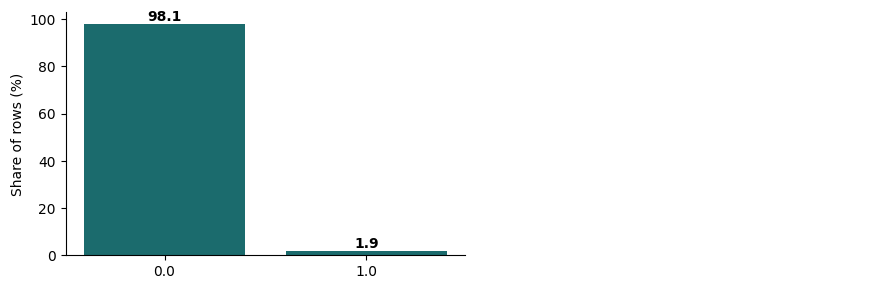

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3)); y = S[TGT].dropna().astype(float)
if y.nunique() <= 10:
    v = y.value_counts(normalize=True).sort_index() * 100; b = ax[0].bar(v.index.astype(str), v.values, color='#1B6B6D'); ax[0].bar_label(b, labels=['%.1f' % x for x in v.values], fontweight='bold'); ax[0].set_ylabel('Share of rows (%)')
    ax[1].axis('off'); print('class counts in the full table:', E[TGT].value_counts().to_dict())
else:
    ax[0].hist(y, bins=50, color='#1B6B6D'); ax[0].set_ylabel('Rows'); ax[0].set_xlabel(TGT)
    ax[1].hist(np.log1p(y.clip(lower=0)), bins=50, color='#F4A261'); ax[1].set_xlabel('log(1 + ' + TGT + ')')
    print(y.describe(percentiles=[.05, .5, .95]).round(3).to_dict())
for a in ax: a.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig('report/fig_eda_target.png', dpi=200); plt.show()

### 2b.6 Phân phối các cột số chính

- **Làm gì:** tám biểu đồ tần suất, đã cắt 1% hai đầu để nhìn rõ phần chính.
- **Kiểm tra:** cột có hai đỉnh thường ứng với hai chế độ vận hành, nên tách ra khi phân tích.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

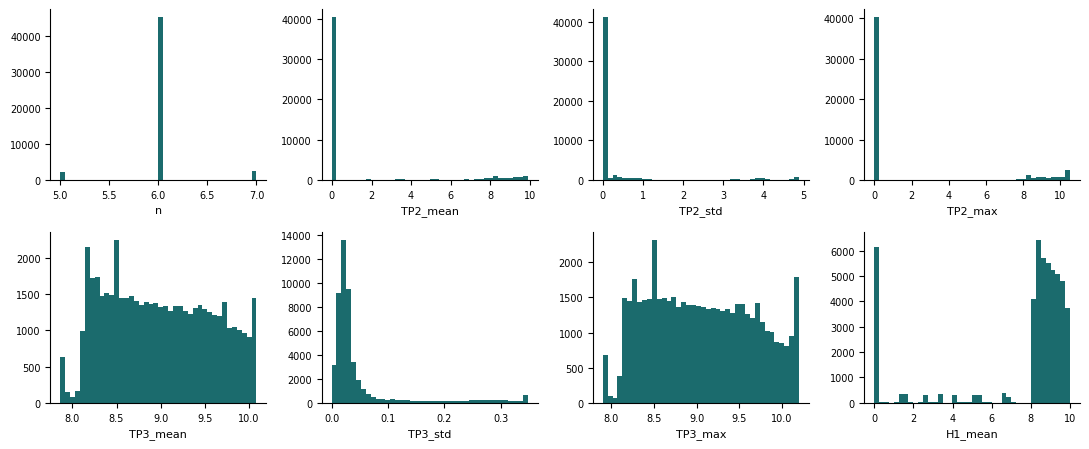

In [11]:
cols = [c for c in NUM if c != TGT][:8]; fig, axes = plt.subplots(2, 4, figsize=(11, 4.6))
for a, c in zip(axes.ravel(), cols):
    x = S[c].dropna().astype(float); x = x.clip(x.quantile(.01), x.quantile(.99)); a.hist(x, bins=40, color='#1B6B6D'); a.set_xlabel(c, fontsize=8); a.spines[['top', 'right']].set_visible(False); a.tick_params(labelsize=7)
for a in axes.ravel()[len(cols):]: a.axis('off')
fig.tight_layout(); fig.savefig('report/fig_eda_distributions.png', dpi=200); plt.show()

### 2b.7 Giá trị ngoại lai

- **Làm gì:** tỷ lệ dòng nằm ngoài 1,5 lần khoảng tứ phân vị của từng cột.
- **Vì sao:** ngoại lai là lỗi đo thì loại và ghi nhật ký; là hiện tượng thật (đỉnh tải, sự cố) thì giữ và nêu trong bài.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [12]:
N_ = S[NUM].astype(float); q1, q3 = N_.quantile(.25), N_.quantile(.75); iqr = q3 - q1
out = (100 * ((N_ < q1 - 1.5 * iqr) | (N_ > q3 + 1.5 * iqr)).mean()).sort_values(ascending=False).round(2).rename('outside_1.5_IQR_pct')
out.to_csv('report/table_outliers.csv'); display(out.head(12).to_frame())

,outside_1.5_IQR_pct
DV_pressure_std,29.63
MPG_share,21.90
COMP_share,21.83
TP2_mean,20.29
DV_eletric_share,20.16
TP2_max,19.68
TP2_std,19.68
Towers_share,18.48
H1_mean,17.47
Motor_current_std,16.35


### 2b.8 Cột nào liên quan tới mục tiêu

- **Làm gì:** tương quan hạng Spearman giữa từng cột số và mục tiêu, vẽ mười cột mạnh nhất.
- **Vì sao:** đây là dự báo sớm về đặc trưng quan trọng; cột tương quan gần 1 có thể là rò rỉ và phải kiểm tra ý nghĩa.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,0
y,0.950
event,0.949
DV_eletric_share,0.306
COMP_share,-0.293
MPG_share,-0.291
Towers_share,-0.272
DV_pressure_mean,0.232
DV_pressure_max,0.232
Oil_temperature_mean,0.228
Oil_temperature_max,0.227


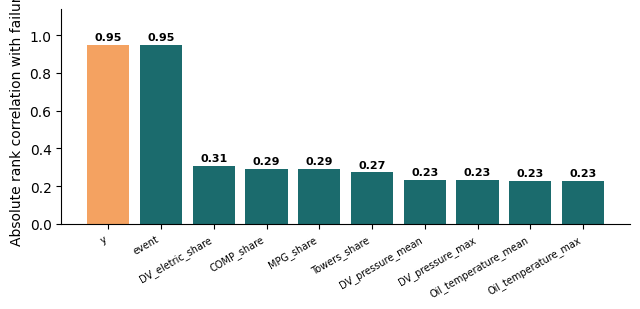

In [13]:
others = [c for c in NUM if c != TGT]
cor = S[others].astype(float).corrwith(S[TGT].astype(float), method='spearman').dropna(); cor = cor.reindex(cor.abs().sort_values(ascending=False).index).head(10)
cor.rename('spearman_with_target').to_csv('report/table_eda_correlation.csv'); display(cor.round(3).to_frame())
if len(cor) and cor.abs().max() > 0: bar_chart(cor.index, cor.abs().values, 'Absolute rank correlation with ' + TGT, 'report/fig_eda_correlation.png', highlight=0, fmt='{:.2f}')

### 2b.9 Các cột mạnh có trùng thông tin không

- **Làm gì:** ma trận tương quan giữa mục tiêu và bảy cột mạnh nhất.
- **Kiểm tra:** hai cột tương quan trên 0,95 với nhau thì chỉ cần giữ một khi giải thích kết quả.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

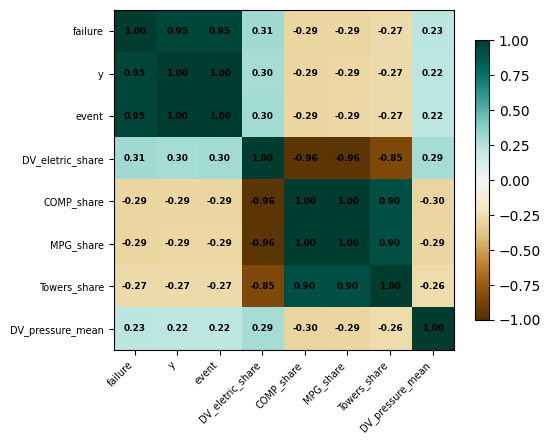

In [14]:
top = [TGT] + list(cor.index[:7]); m = S[top].astype(float).corr(method='spearman'); fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(m, cmap='BrBG', vmin=-1, vmax=1); ax.set_xticks(range(len(top))); ax.set_yticks(range(len(top))); ax.set_xticklabels(top, rotation=45, ha='right', fontsize=7); ax.set_yticklabels(top, fontsize=7)
for i in range(len(top)):
    for j in range(len(top)): ax.text(j, i, '%.2f' % m.iloc[i, j], ha='center', va='center', fontsize=6.5, fontweight='bold')
fig.colorbar(im, shrink=0.8); fig.tight_layout(); fig.savefig('report/fig_eda_heatmap.png', dpi=200); plt.show()

### 2b.10 Mục tiêu theo nhóm

- **Làm gì:** số dòng, trung bình, trung vị và độ lệch chuẩn của mục tiêu theo cột nhóm, kèm hình.
- **Vì sao:** khác biệt giữa các nhóm là gợi ý trực tiếp cho RQ1 và cho cách chia dữ liệu ở Notebook B.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,rows,mean,median,std
month,,,,
3,38113,0.000,0.0,0.000
7,36996,0.007,0.0,0.085
6,36629,0.078,0.0,0.268
8,36449,0.000,0.0,0.000
5,35651,0.011,0.0,0.104
2,35525,0.000,0.0,0.000
4,33268,0.043,0.0,0.203
9,89,0.000,0.0,0.000


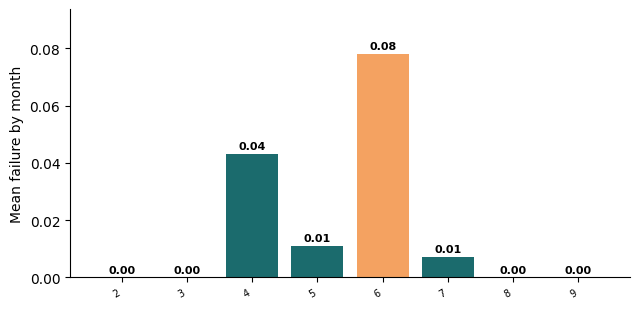

In [15]:
g = E.assign(_t=E[TGT].astype(float)).groupby(GRP)['_t'].agg(['size', 'mean', 'median', 'std']).rename(columns={'size': 'rows'})
g.to_csv('report/table_eda_by_group.csv'); display(g.sort_values('rows', ascending=False).head(15).round(3))
gg = g.sort_values('rows', ascending=False).head(12).sort_index()
if gg['mean'].min() >= 0 and gg['mean'].max() > 0: v, lab, f = nice(gg['mean'], 'Mean ' + TGT + ' by ' + GRP); bar_chart(gg.index.astype(str), v, lab, 'report/fig_eda_by_group.png', highlight=int(v.argmax()), fmt=f)

### Tổng hợp EDA

| Quan sát (có số) | Bằng chứng (bảng, hình) | Ảnh hưởng tới câu hỏi nào | Việc cần làm |
|---|---|---|---|
| | | | |
| | | | |
| | | | |
| | | | |
| | | | |

## Bước 3. Truy vấn dữ liệu bằng SQL

- **Làm gì:** ghi mọi truy vấn vào `sql/queries.sql`, rồi chạy **từng truy vấn một ô** để đọc kết quả và viết nhận xét.
- **Vì sao:** RQ1 được trả lời bằng bảng số; bảng `feat` là đầu vào của Notebook B.
- **Kiểm tra:** tính tay một nhóm nhỏ và so với kết quả truy vấn.

In [16]:
SQL = r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE apu AS SELECT * FROM 'data/processed/metropt.parquet';
-- Q1: windows, failure minutes and frozen-logger minutes per month
SELECT month, COUNT(*) AS minutes, SUM(failure) AS failure_minutes, SUM(frozen) AS frozen_minutes, COUNT(DISTINCT CASE WHEN event > 0 THEN event END) AS events FROM apu GROUP BY 1 ORDER BY 1;
-- Q2: signals in normal operation and during reported air leaks
SELECT failure, COUNT(*) AS minutes, AVG(TP2_mean) AS tp2, AVG(TP3_mean) AS tp3, AVG(Oil_temperature_mean) AS oil_temp, AVG(Motor_current_mean) AS motor_current,
       AVG(COMP_share) AS comp_share, AVG(DV_pressure_mean) AS dv_pressure FROM apu GROUP BY 1 ORDER BY 1;
-- Q3: daily compressor duty and its 7-day moving average (window function)
SELECT day, duty, AVG(duty) OVER (ORDER BY day ROWS BETWEEN 6 PRECEDING AND CURRENT ROW) AS duty_7d
FROM (SELECT CAST(ts AS DATE) AS day, AVG(1 - COMP_share) AS duty FROM apu GROUP BY 1) ORDER BY day LIMIT 20;
-- Q4: model table; rolling features use the current and earlier minutes only
CREATE OR REPLACE TABLE feat AS
SELECT *, AVG(TP2_mean) OVER w15 AS TP2_m15, AVG(Oil_temperature_mean) OVER w15 AS Oil_m15, AVG(Motor_current_mean) OVER w15 AS Motor_m15,
       AVG(DV_pressure_mean) OVER w15 AS DV_m15, AVG(COMP_share) OVER w60 AS COMP_m60, AVG(TP3_mean) OVER w60 AS TP3_m60, AVG(Oil_temperature_mean) OVER w60 AS Oil_m60,
       MAX(DV_pressure_max) OVER w60 AS DV_max60
FROM apu WINDOW w15 AS (ORDER BY ts ROWS BETWEEN 14 PRECEDING AND CURRENT ROW), w60 AS (ORDER BY ts ROWS BETWEEN 59 PRECEDING AND CURRENT ROW);
SELECT y, COUNT(*) AS n FROM feat GROUP BY 1;
"""
open('sql/queries.sql', 'w').write(SQL)

1643

In [17]:
import duckdb
con = duckdb.connect(); QN = 0
def run(stmt):                                           # runs one statement; a SELECT is shown, saved and plotted when the result is small
    global QN
    body = '\n'.join(l for l in stmt.split('\n') if not l.strip().startswith('--')).strip()
    if not body.upper().startswith(('SELECT', 'WITH', 'SUMMARIZE')): con.execute(stmt); print('done'); return None
    QN += 1; r = con.execute(stmt).df(); r.to_csv('report/table_q%d.csv' % QN, index=False); display(r.head(15))
    numc = [c for c in r.columns[1:] if pd.api.types.is_numeric_dtype(r[c])]
    if 2 <= len(r) <= 30 and numc and r[numc[0]].notna().all() and r[numc[0]].min() >= 0 and r[numc[0]].max() > 0:
        v, lab, f = nice(r[numc[0]], numc[0]); bar_chart(r.iloc[:, 0].astype(str), v, lab, 'report/fig_q%d.png' % QN, highlight=int(v.argmax()), fmt=f)
    return r

### Step 3: sql/queries.sql

- **Làm gì:** chạy truy vấn.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

In [18]:
r = run(r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE apu AS SELECT * FROM 'data/processed/metropt.parquet';""")

done


### Q1: windows, failure minutes and frozen-logger minutes per month

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,month,minutes,failure_minutes,frozen_minutes,events
0,2,35525,0.0,0.0,0
1,3,38113,0.0,29.0,0
2,4,33268,1436.0,2182.0,1
3,5,35651,391.0,2507.0,1
4,6,36629,2863.0,4626.0,1
5,7,36996,270.0,878.0,1
6,8,36449,0.0,0.0,0
7,9,89,0.0,0.0,0


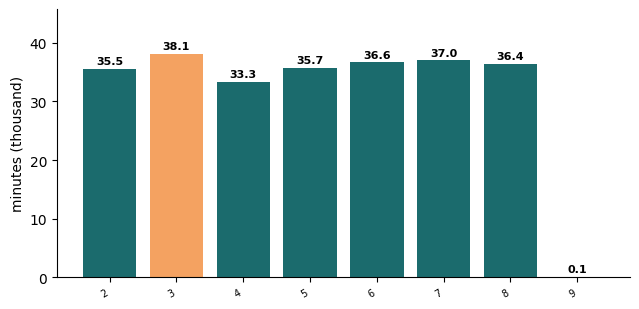

In [19]:
r = run(r"""-- Q1: windows, failure minutes and frozen-logger minutes per month
SELECT month, COUNT(*) AS minutes, SUM(failure) AS failure_minutes, SUM(frozen) AS frozen_minutes, COUNT(DISTINCT CASE WHEN event > 0 THEN event END) AS events FROM apu GROUP BY 1 ORDER BY 1;""")

### Q2: signals in normal operation and during reported air leaks

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,failure,minutes,tp2,tp3,oil_temp,motor_current,comp_share,dv_pressure
0,0,247760,1.246276,8.994810,62.384126,1.986733,0.850979,0.019323
1,1,4960,8.104714,8.287166,75.571861,5.526229,0.005477,1.856984


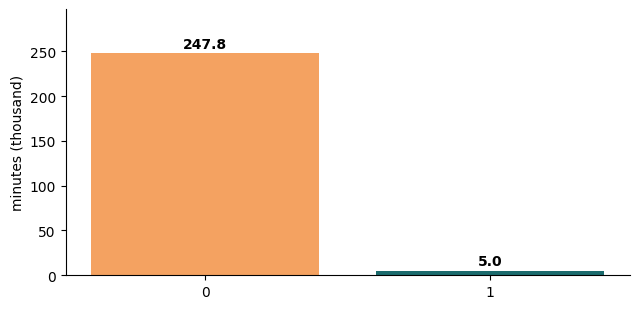

In [20]:
r = run(r"""-- Q2: signals in normal operation and during reported air leaks
SELECT failure, COUNT(*) AS minutes, AVG(TP2_mean) AS tp2, AVG(TP3_mean) AS tp3, AVG(Oil_temperature_mean) AS oil_temp, AVG(Motor_current_mean) AS motor_current,
       AVG(COMP_share) AS comp_share, AVG(DV_pressure_mean) AS dv_pressure FROM apu GROUP BY 1 ORDER BY 1;""")

### Q3: daily compressor duty and its 7-day moving average (window function)

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,day,duty,duty_7d
0,2020-02-01,0.060882,0.060882
1,2020-02-02,0.066055,0.063468
2,2020-02-03,0.052183,0.059706
3,2020-02-04,0.061690,0.060202
4,2020-02-05,0.068602,0.061882
5,2020-02-06,0.059620,0.061505
6,2020-02-07,0.068811,0.062549
7,2020-02-08,0.077887,0.064978
8,2020-02-09,0.065516,0.064901
9,2020-02-10,0.058522,0.065807


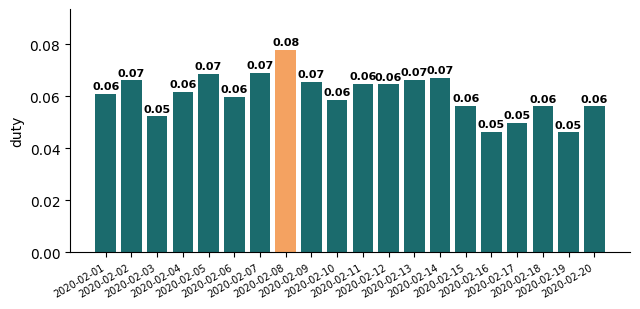

In [21]:
r = run(r"""-- Q3: daily compressor duty and its 7-day moving average (window function)
SELECT day, duty, AVG(duty) OVER (ORDER BY day ROWS BETWEEN 6 PRECEDING AND CURRENT ROW) AS duty_7d
FROM (SELECT CAST(ts AS DATE) AS day, AVG(1 - COMP_share) AS duty FROM apu GROUP BY 1) ORDER BY day LIMIT 20;""")

### Q4: model table; rolling features use the current and earlier minutes only

- **Làm gì:** chạy truy vấn.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

In [22]:
r = run(r"""-- Q4: model table; rolling features use the current and earlier minutes only
CREATE OR REPLACE TABLE feat AS
SELECT *, AVG(TP2_mean) OVER w15 AS TP2_m15, AVG(Oil_temperature_mean) OVER w15 AS Oil_m15, AVG(Motor_current_mean) OVER w15 AS Motor_m15,
       AVG(DV_pressure_mean) OVER w15 AS DV_m15, AVG(COMP_share) OVER w60 AS COMP_m60, AVG(TP3_mean) OVER w60 AS TP3_m60, AVG(Oil_temperature_mean) OVER w60 AS Oil_m60,
       MAX(DV_pressure_max) OVER w60 AS DV_max60
FROM apu WINDOW w15 AS (ORDER BY ts ROWS BETWEEN 14 PRECEDING AND CURRENT ROW), w60 AS (ORDER BY ts ROWS BETWEEN 59 PRECEDING AND CURRENT ROW);""")

done


### Statement 6

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,y,n
0,0,247280
1,1,5440


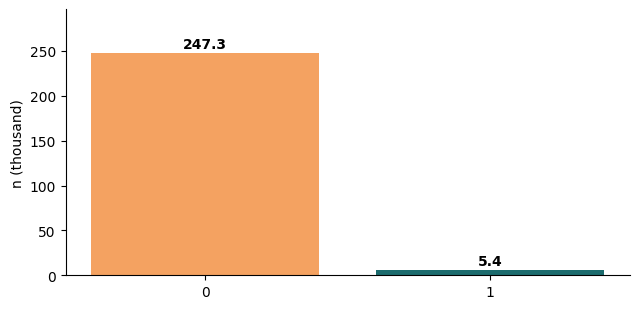

In [23]:
r = run(r"""SELECT y, COUNT(*) AS n FROM feat GROUP BY 1;""")

### Truy vấn bổ sung 1: hồ sơ của bảng làm việc

- **Làm gì:** `SUMMARIZE` cho biết min, max, số giá trị khác nhau và tỷ lệ thiếu của mọi cột bằng một lệnh SQL.
- **Kiểm tra:** so với bảng thống kê mô tả ở mục 2b.3.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [24]:
r = run('''SELECT column_name, column_type, min, max, approx_unique, null_percentage FROM (SUMMARIZE apu)''')

,column_name,column_type,min,max,approx_unique,null_percentage
0,ts,TIMESTAMP,2020-02-01 00:00:00,2020-09-01 03:59:00,275026,0.0
1,n,BIGINT,1,7,7,0.0
2,TP2_mean,DOUBLE,-0.02566666666666602,10.497000000000002,28729,0.0
3,TP2_std,DOUBLE,0.0,5.279027782966607,44169,0.0
4,TP2_max,DOUBLE,-0.0240000000000009,10.676,3240,0.0
5,TP3_mean,DOUBLE,0.8080000000000004,10.251999999999999,26595,0.0
6,TP3_std,DOUBLE,0.0,3.165400115133771,120364,0.0
7,TP3_max,DOUBLE,0.8879999999999999,10.302,1845,0.0
8,H1_mean,DOUBLE,-0.025999999999999763,10.192,33063,0.0
9,H1_std,DOUBLE,0.0,5.117347837394766,120233,0.0


### Truy vấn bổ sung 2: các phân vị của mục tiêu

- **Làm gì:** phân vị 5%, 25%, 50%, 75%, 95% và 99% của cột mục tiêu.
- **Vì sao:** các phân vị này dùng để chọn ngưỡng, thang trục và cách cắt đuôi khi vẽ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [25]:
r = run('''SELECT COUNT(*) AS n, MIN("failure") AS min, QUANTILE_CONT("failure", 0.05) AS p05, QUANTILE_CONT("failure", 0.25) AS p25, MEDIAN("failure") AS p50, QUANTILE_CONT("failure", 0.75) AS p75, QUANTILE_CONT("failure", 0.95) AS p95, QUANTILE_CONT("failure", 0.99) AS p99, MAX("failure") AS max FROM apu''')

,n,min,p05,p25,p50,p75,p95,p99,max
0,252720,0,0.0,0.0,0.0,0.0,0.0,1.0,1


### Truy vấn bổ sung 3: xếp hạng các nhóm

- **Làm gì:** số dòng và trung bình mục tiêu theo nhóm, xếp hạng bằng hàm cửa sổ `RANK`, kèm tỷ trọng của nhóm trong toàn bảng.
- **Vì sao:** nhóm lớn nhất và nhóm lệch nhất thường là ví dụ minh hoạ trong mục Results.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,grp,mean_target,n,pct_of_rows,rank_by_mean
0,6,0.078162,36629,14.493906,1
1,4,0.043165,33268,13.163976,2
2,5,0.010967,35651,14.106917,3
3,7,0.007298,36996,14.639126,4
4,8,0.000000,36449,14.422681,5
5,2,0.000000,35525,14.057059,5
6,3,0.000000,38113,15.081117,5
7,9,0.000000,89,0.035217,5


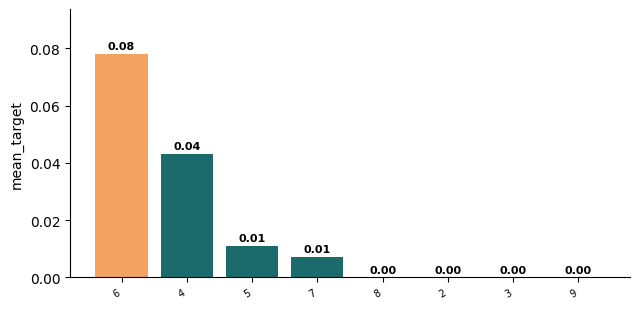

In [26]:
r = run('''SELECT CAST("month" AS VARCHAR) AS grp, AVG("failure") AS mean_target, COUNT(*) AS n, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS pct_of_rows, RANK() OVER (ORDER BY AVG("failure") DESC) AS rank_by_mean FROM apu GROUP BY 1 ORDER BY 5 LIMIT 15''')

### Truy vấn bổ sung 4: bảng mô hình có sạch không

- **Làm gì:** kiểu dữ liệu, tỷ lệ thiếu và số giá trị khác nhau của từng cột trong bảng `feat`.
- **Kiểm tra:** cột đặc trưng nào còn thiếu thì phải xử lý trước khi sang Notebook B.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [27]:
r = run('''SELECT column_name, column_type, null_percentage, approx_unique FROM (SUMMARIZE feat) ORDER BY null_percentage DESC LIMIT 20''')

,column_name,column_type,null_percentage,approx_unique
0,ts,TIMESTAMP,0.0,275026
1,n,BIGINT,0.0,7
2,TP2_mean,DOUBLE,0.0,28729
3,TP2_std,DOUBLE,0.0,44169
4,TP2_max,DOUBLE,0.0,3240
5,TP3_mean,DOUBLE,0.0,26595
6,TP3_std,DOUBLE,0.0,120364
7,TP3_max,DOUBLE,0.0,1845
8,H1_mean,DOUBLE,0.0,33063
9,H1_std,DOUBLE,0.0,120233


## Bước 5. Hình RQ1

- **Làm gì:** vẽ một biểu đồ cột từ kết quả SQL bằng hàm vẽ chuẩn của nhóm.
- **Vì sao:** người đọc phải thấy kết luận của RQ1 trong vài giây.
- **Kiểm tra:** chữ tiếng Anh, không viền trên và phải, số in đậm trên cột, không chữ đè cột. Viết caption nêu kết luận, không mô tả trục.

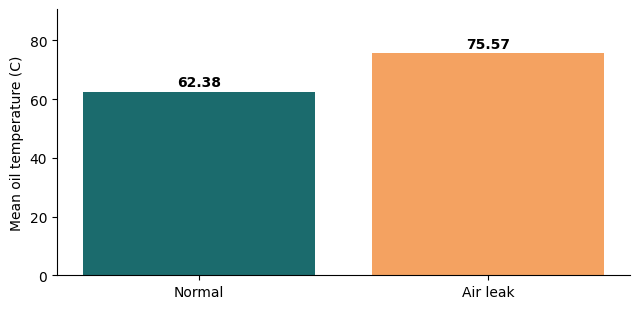

In [28]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

fig1 = con.execute("""SELECT CASE WHEN failure = 1 THEN 'Air leak' ELSE 'Normal' END AS g, AVG(Oil_temperature_mean) AS v FROM apu GROUP BY 1 ORDER BY 1 DESC""").df()
bar_chart(fig1.g, fig1.v, 'Mean oil temperature (C)', 'report/fig_rq1.png', highlight=int(fig1.v.idxmax()), fmt='{:.2f}')

## Bàn giao và test case

- **Làm gì:** ghi `manifest.json` (số dòng, số cột, mã băm) và chạy các kiểm tra tự động.
- **Vì sao:** Notebook B đọc manifest trước khi chạy, nên hai người làm song song mà không lệch dữ liệu.
- **Kiểm tra:** mọi `assert` qua. Sinh viên B chạy lại notebook này trên máy mình và ghi vào ô Đối chứng.

In [29]:
import json, hashlib
path = 'data/processed/metropt.parquet'; t = pd.read_parquet(path)
feat_n = con.execute('SELECT COUNT(*) FROM feat').fetchone()[0]
manifest = {'file': path, 'rows': len(t), 'columns': t.shape[1], 'feat_rows': feat_n,
            'md5': hashlib.md5(open(path, 'rb').read()).hexdigest()}
json.dump(manifest, open('data/processed/manifest.json', 'w'), indent=2); print(manifest)
assert feat_n > 0 and os.path.exists('sql/queries.sql') and os.path.exists('report/table_cleaning_log.csv')
print('Notebook A: all checks passed')

{'file': 'data/processed/metropt.parquet', 'rows': 252720, 'columns': 37, 'feat_rows': 252720, 'md5': 'e331ace11be4b0aac570a88a76aa0fc4'}
Notebook A: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Số dòng | md5 khớp | Ghi chú |
|---|---|---|---|---|
| | | | | |

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: